# Etapa 4 — Satisfação do Cliente
**Tech Challenge Pós-Tech — Fase 1**

Análise reproduzível com as bases tratadas do projeto. Unidade principal: **pedido** (não item). Notas baixas = 1–2; altas = 4–5. O risco de churn é apenas um **sinal de insatisfação**, não uma previsão validada de abandono.

In [57]:
# %pip install nbformat nbconvert ipykernel

%run ../src/librarys.ipynb

In [58]:
# Configurando os gráficos
plt.style.use('seaborn-v0_8-whitegrid')
plt.rcParams['figure.figsize'] = (10, 5)
plt.rcParams['font.size'] = 11

# Localizando a pasta dos dados
DATA = Path('../data/processed')

print('Pasta de dados:', DATA.resolve())

Pasta de dados: C:\Users\robin\OneDrive\Documentos\FIAP\Entregas\Tech-challenge-POSTECH-main\Tech-challenge-POSTECH-main\data\processed


## 1. Preparação, qualidade e granularidade
As avaliações podem conter mais de um registro por pedido. Para não duplicar pedidos, consolidamos a nota por `order_id` (última avaliação registrada). Para análises de categoria, cada pedido recebe sua **categoria de maior valor de itens**, evitando multiplicar avaliações em pedidos com vários produtos.

In [59]:
# Carregando os dados
orders = pd.read_csv(DATA / 'orders_enriched.csv')
reviews = pd.read_csv(DATA / 'reviews.csv')
items = pd.read_csv(DATA / 'order_items_category.csv')
customers = pd.read_csv(DATA / 'customers.csv')

In [60]:
# Convertendo as datas
colunas_datas = [
    'order_purchase_timestamp',
    'order_delivered_customer_date',
    'order_estimated_delivery_date'
]

for coluna in colunas_datas:
    orders[coluna] = pd.to_datetime(orders[coluna], errors='coerce')

reviews['review_creation_date'] = pd.to_datetime(reviews['review_creation_date'])
reviews['review_answer_timestamp'] = pd.to_datetime(reviews['review_answer_timestamp'])

In [61]:
# Organizando as avaliações
reviews['review_score'] = pd.to_numeric(reviews['review_score'], errors='coerce')

reviews = reviews.sort_values(
    ['review_creation_date', 'review_answer_timestamp']
).drop_duplicates('order_id', keep='last')

In [62]:
# Juntando os pedidos com as avaliações
base = orders.drop(columns=['review_score'], errors='ignore').merge(
    reviews[['order_id', 'review_score', 'review_comment_message']],
    on='order_id',
    how='left'
)

In [63]:
# Calculando o tempo de entrega e os atrasos
base['dias_entrega'] = (
    base['order_delivered_customer_date'] - base['order_purchase_timestamp']
).dt.total_seconds() / 86400

base['dias_atraso'] = (
    base['order_delivered_customer_date'] - base['order_estimated_delivery_date']
).dt.total_seconds() / 86400

base['atrasado'] = base['dias_atraso'] > 0

In [64]:
# Classificando a satisfação dos clientes
base['faixa_nota'] = pd.cut(
    base['review_score'],
    bins=[0, 2, 3, 5],
    labels=['Insatisfeito', 'Neutro', 'Satisfeito']
)

base['avaliacao_baixa'] = base['review_score'] <= 2

In [65]:
# Conferindo os resultados
print('Total de pedidos:', len(base))
print('Pedidos avaliados:', base['review_score'].notna().sum())

display(base[['review_score', 'dias_entrega', 'dias_atraso', 'order_total']].describe().round(2))


Total de pedidos: 99441
Pedidos avaliados: 98673


,review_score,dias_entrega,dias_atraso,order_total
count,98673.00,96476.00,96476.00,98666.00
mean,4.09,12.56,-11.18,160.58
std,1.35,9.55,10.19,220.47
min,1.00,0.53,-146.02,9.59
25%,4.00,6.77,-16.24,61.98
50%,5.00,10.22,-11.95,105.29
75%,5.00,15.72,-6.39,176.87
max,5.00,209.63,188.98,13664.08


## 2. Distribuição de notas e indicadores executivos

,Indicador,Valor
0,Pedidos avaliados,"98,673"
1,Nota média,4.09
2,% notas 1–2,14.7%
3,% notas 4–5,77.1%


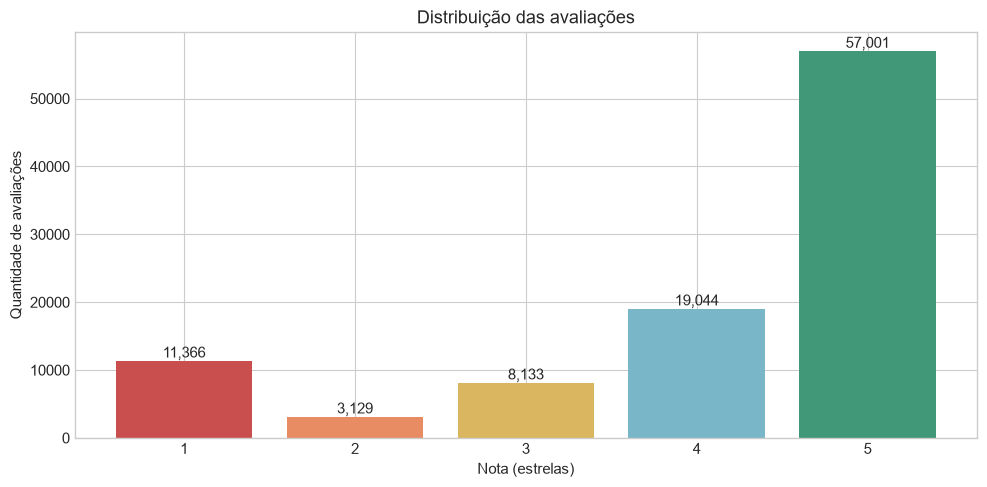

In [66]:
avaliados = base[base.review_score.between(1,5)].copy()
notas = avaliados.review_score.value_counts().reindex(range(1,6),fill_value=0).sort_index()
indicadores = pd.DataFrame({'Indicador':['Pedidos avaliados','Nota média','% notas 1–2','% notas 4–5'], 'Valor':[f'{len(avaliados):,}',f'{avaliados.review_score.mean():.2f}',f'{avaliados.avaliacao_baixa.mean():.1%}',f'{avaliados.review_score.ge(4).mean():.1%}']})
display(indicadores)
fig,ax=plt.subplots(); bars=ax.bar(notas.index.astype(str),notas.values,color=['#c94f4f','#e78c63','#d9b65f','#79b6c7','#409878'])
for bar in bars: ax.text(bar.get_x()+bar.get_width()/2,bar.get_height(),f'{int(bar.get_height()):,}',ha='center',va='bottom')
ax.set(title='Distribuição das avaliações',xlabel='Nota (estrelas)',ylabel='Quantidade de avaliações');plt.tight_layout();plt.show()

## 3. Tempo de entrega e atrasos
A comparação é **descritiva**, não demonstra causalidade. O atraso é calculado apenas para pedidos com entrega e previsão registradas.

,pedidos,nota_media,pct_notas_baixas,dias_entrega_medios
atrasado,,,,
False,88163,4.294,0.092,10.878
True,7661,2.565,0.541,31.379


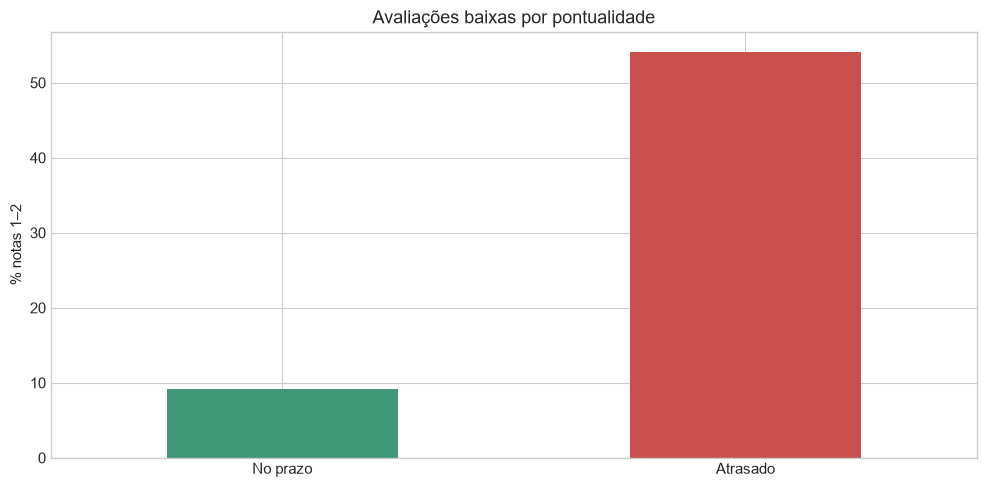

,pedidos,nota_media,pct_baixa
faixa_entrega,,,
Até 7d,25933,4.418,0.074
8–14d,39997,4.312,0.090
15–21d,17582,4.138,0.117
22–30d,7882,3.608,0.243
Mais de 30d,4430,2.253,0.630


In [67]:
entregues = avaliados[(avaliados.order_status=='DELIVERED') & avaliados.dias_entrega.ge(0) & avaliados.dias_atraso.notna()].copy()
resumo_atraso=entregues.groupby('atrasado',observed=True).agg(pedidos=('order_id','size'),nota_media=('review_score','mean'),pct_notas_baixas=('avaliacao_baixa','mean'),dias_entrega_medios=('dias_entrega','mean')).round(3)
display(resumo_atraso)
fig,ax=plt.subplots(); resumo_atraso['pct_notas_baixas'].mul(100).plot.bar(ax=ax,color=['#409878','#c94f4f'],rot=0)
ax.set_xticklabels(['No prazo','Atrasado']);ax.set(title='Avaliações baixas por pontualidade',ylabel='% notas 1–2',xlabel='');plt.tight_layout();plt.show()
entregues['faixa_entrega']=pd.cut(entregues.dias_entrega,[0,7,14,21,30,np.inf],labels=['Até 7d','8–14d','15–21d','22–30d','Mais de 30d'],include_lowest=True)
display(entregues.groupby('faixa_entrega',observed=True).agg(pedidos=('order_id','size'),nota_media=('review_score','mean'),pct_baixa=('avaliacao_baixa','mean')).round(3))

## 4. Preço do pedido e satisfação
O valor usado é `order_total` por pedido, não o valor de cada linha de item. Faixas por quartis observados.

,pedidos,valor_medio,nota_media,pct_baixa
faixa_valor,,,,
"(9.589, 61.87]",24481,42.918,4.193,0.117
"(61.87, 105.28]",24506,81.660,4.130,0.134
"(105.28, 176.74]",24452,137.224,4.107,0.141
"(176.74, 13664.08]",24478,379.631,3.988,0.176


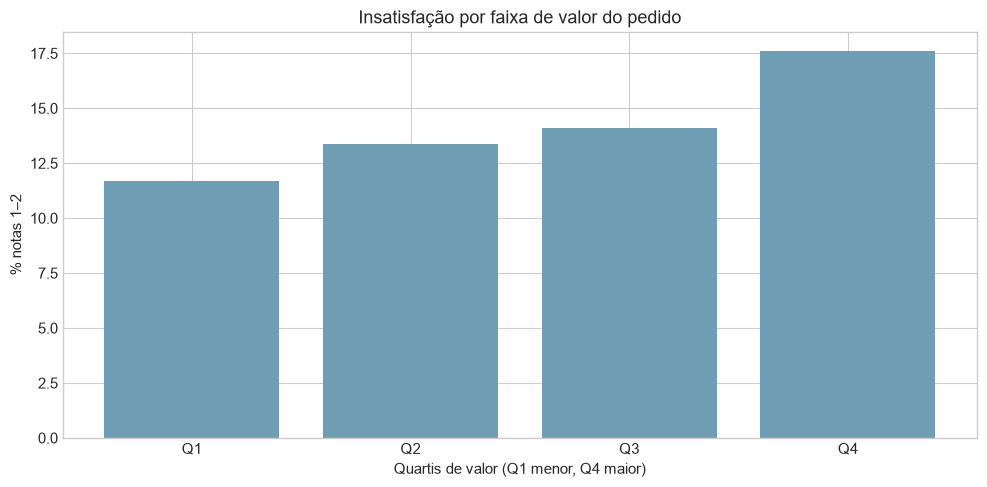

In [68]:
precos=avaliados[avaliados.order_total.notna() & (avaliados.order_total>=0)].copy()
precos['faixa_valor']=pd.qcut(precos.order_total,q=4,duplicates='drop')
por_preco=precos.groupby('faixa_valor',observed=True).agg(pedidos=('order_id','size'),valor_medio=('order_total','mean'),nota_media=('review_score','mean'),pct_baixa=('avaliacao_baixa','mean'))
display(por_preco.round(3))
fig,ax=plt.subplots();ax.bar(range(len(por_preco)),por_preco.pct_baixa*100,color='#6e9db4');ax.set_xticks(range(len(por_preco)),[f'Q{i+1}' for i in range(len(por_preco))]);ax.set(title='Insatisfação por faixa de valor do pedido',xlabel='Quartis de valor (Q1 menor, Q4 maior)',ylabel='% notas 1–2');plt.tight_layout();plt.show()

## 5. Categorias associadas à satisfação
Para cada pedido, atribuímos a categoria com **maior soma de preço dos itens**. Em empates, a ordenação é estável. Exibimos apenas categorias com pelo menos 100 pedidos avaliados.

,pedidos,nota_media,pct_baixa
categoria,,,
FASHION_ROUPA_MASCULINA,111,3.703,0.261
MOVEIS_ESCRITORIO,1260,3.620,0.226
AUDIO,343,3.843,0.216
CONSTRUCAO_FERRAMENTAS_SEGURANCA,161,3.888,0.193
SEM CATEGORIA,1399,3.941,0.192
TELEFONIA_FIXA,214,3.902,0.187
CASA_CONFORTO,357,3.905,0.185
FASHION_UNDERWEAR_E_MODA_PRAIA,120,3.933,0.183
CAMA_MESA_BANHO,9247,3.977,0.166


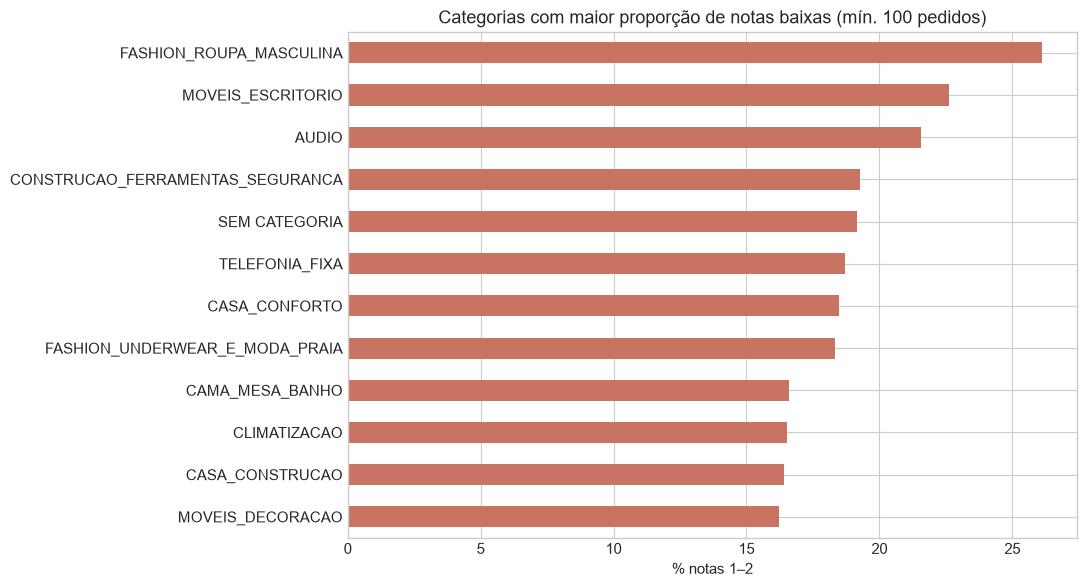

In [69]:
items['price']=pd.to_numeric(items['price'],errors='coerce').fillna(0)
items['categoria']=items['product_category_name'].fillna('SEM_CATEGORIA')
cat_valor=items.groupby(['order_id','categoria'],as_index=False)['price'].sum()
cat_principal=(cat_valor.sort_values(['order_id','price','categoria'],ascending=[True,False,True]).drop_duplicates('order_id')[['order_id','categoria']])
cat_base=avaliados.merge(cat_principal,on='order_id',how='left',validate='one_to_one')
por_categoria=cat_base.groupby('categoria').agg(pedidos=('order_id','size'),nota_media=('review_score','mean'),pct_baixa=('avaliacao_baixa','mean')).query('pedidos >= 100').sort_values('pct_baixa',ascending=False)
display(por_categoria.head(15).round(3))
fig,ax=plt.subplots(figsize=(11,6));por_categoria.head(12).sort_values('pct_baixa').pct_baixa.mul(100).plot.barh(ax=ax,color='#c97462');ax.set(title='Categorias com maior proporção de notas baixas (mín. 100 pedidos)',xlabel='% notas 1–2',ylabel='');plt.tight_layout();plt.show()

## 6. Comentários: temas recorrentes
Mineração exploratória baseada em palavras-chave (não é análise de sentimento supervisionada). Um comentário pode conter vários temas; a ausência de menção não indica ausência do problema.

,tema,mencoes,pct_notas_baixas_nas_mencoes
1,Produto/qualidade,18842,0.321
0,Entrega/atraso,15426,0.232
2,Atendimento,2175,0.451
3,Preço/valor,1370,0.268
4,Embalagem,958,0.458


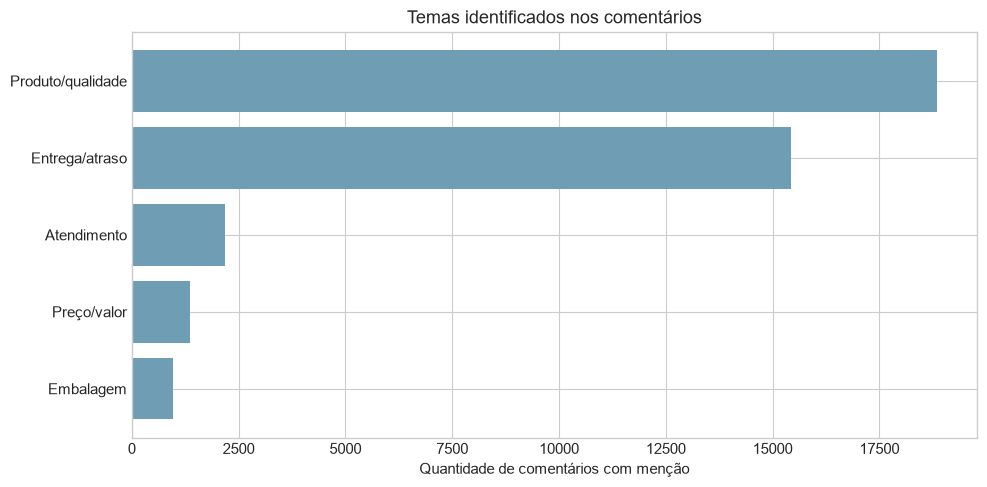

In [70]:
import re, unicodedata
def normalizar_texto(x):
    s=unicodedata.normalize('NFKD',str(x).lower());return ''.join(c for c in s if not unicodedata.combining(c))
comentarios=avaliados[avaliados.review_comment_message.notna() & avaliados.review_comment_message.astype(str).str.strip().ne('')].copy()
comentarios['texto']=comentarios.review_comment_message.map(normalizar_texto)
temas={'Entrega/atraso':r'atrasa|demor|entreg|prazo|transport', 'Produto/qualidade':r'quebrad|defeit|qualidade|danific|estragad|produto', 'Atendimento':r'atendiment|suporte|vendedor|respost|contato', 'Preço/valor':r'preco|caro|valor|custo', 'Embalagem':r'embalag|pacote|caixa|embrulh'}
linhas=[]
for tema,regex in temas.items():
    m=comentarios.texto.str.contains(regex,regex=True,na=False)
    linhas.append({'tema':tema,'mencoes':int(m.sum()),'pct_notas_baixas_nas_mencoes':comentarios.loc[m,'avaliacao_baixa'].mean()})
tabela_temas=pd.DataFrame(linhas).sort_values('mencoes',ascending=False)
display(tabela_temas.round(3))
fig,ax=plt.subplots();ax.barh(tabela_temas.tema[::-1],tabela_temas.mencoes[::-1],color='#6e9db4');ax.set(title='Temas identificados nos comentários',xlabel='Quantidade de comentários com menção');plt.tight_layout();plt.show()

## 7. Sinais de risco de churn (proxy)
**Limitação:** não existe rótulo de churn no dataset. Classificamos como sinal de risco clientes cuja **última compra avaliada** recebeu nota 1–2. Isso não equivale a churn real nem a uma probabilidade. `customer_unique_id` permite acompanhar múltiplos pedidos do mesmo cliente.

In [71]:
clientes=customers[['customer_id','customer_unique_id']].drop_duplicates('customer_id')
risco=avaliados.merge(clientes,on='customer_id',how='left',validate='many_to_one').dropna(subset=['customer_unique_id'])
risco=risco.sort_values(['order_purchase_timestamp','order_id']).drop_duplicates('customer_unique_id',keep='last')
risco['sinal_risco']=risco.review_score.le(2)
display(pd.DataFrame({'Indicador':['Clientes com última compra avaliada','Clientes com sinal de risco','% com sinal de risco'], 'Valor':[len(risco),int(risco.sinal_risco.sum()),f'{risco.sinal_risco.mean():.1%}']}))
print('Observação: clientes sem avaliação não entram nessa proxy; a base não informa se voltaram a comprar após 2018.')

,Indicador,Valor
0,Clientes com última compra avaliada,95380
1,Clientes com sinal de risco,14028
2,% com sinal de risco,14.7%


Observação: clientes sem avaliação não entram nessa proxy; a base não informa se voltaram a comprar após 2018.


## 8. Síntese executiva automatizada e recomendações
As conclusões abaixo são produzidas a partir dos dados carregados, não de números fixos. As recomendações são hipóteses de ação a validar em testes.

In [72]:
pct_baixas=avaliados.avaliacao_baixa.mean()*100
pontual=resumo_atraso.loc[False,'pct_notas_baixas']*100 if False in resumo_atraso.index else np.nan
atrasado=resumo_atraso.loc[True,'pct_notas_baixas']*100 if True in resumo_atraso.index else np.nan
print(f'• {len(avaliados):,} pedidos avaliados; nota média {avaliados.review_score.mean():.2f}/5; {pct_baixas:.1f}% receberam 1–2 estrelas.')
print(f'• Pedidos no prazo: {pontual:.1f}% de notas baixas; pedidos atrasados: {atrasado:.1f}%.')
if len(por_categoria): print(f'• Entre categorias com pelo menos 100 pedidos, maior percentual de avaliações baixas: {por_categoria.index[0]} ({por_categoria.iloc[0].pct_baixa:.1%}).')
print(f'• {risco.sinal_risco.mean():.1%} dos clientes com última compra avaliada têm sinal de risco (proxy, não churn observado).')
print('\nRecomendações para avaliação: priorizar redução de atrasos; auditar categorias com maior insatisfação; analisar reclamações recorrentes; acompanhar métricas por coorte e testar intervenções.')
print('Cuidados: relações descritivas não demonstram causalidade; comentários são amostra autoselecionada; não chamar a nota de NPS.')

• 98,673 pedidos avaliados; nota média 4.09/5; 14.7% receberam 1–2 estrelas.
• Pedidos no prazo: 9.2% de notas baixas; pedidos atrasados: 54.1%.
• Entre categorias com pelo menos 100 pedidos, maior percentual de avaliações baixas: FASHION_ROUPA_MASCULINA (26.1%).
• 14.7% dos clientes com última compra avaliada têm sinal de risco (proxy, não churn observado).

Recomendações para avaliação: priorizar redução de atrasos; auditar categorias com maior insatisfação; analisar reclamações recorrentes; acompanhar métricas por coorte e testar intervenções.
Cuidados: relações descritivas não demonstram causalidade; comentários são amostra autoselecionada; não chamar a nota de NPS.


## 9. Conclusões

A análise de satisfação dos clientes mostrou resultados positivos, com uma **nota média de 4,09**, indicando que a maioria das avaliações foi favorável.

O tempo de entrega é um dos pontos importantes para a experiência do cliente. Por isso, acompanhar os atrasos e identificar possíveis problemas logísticos pode ajudar a reduzir a insatisfação.

A análise dos valores dos pedidos e das categorias também permite identificar padrões de avaliação e encontrar oportunidades de melhoria em determinados grupos de produtos.